config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTMAEModel LOAD REPORT from: facebook/vit-mae-base
Key                                                                     | Status     |  | 
------------------------------------------------------------------------+------------+--+-
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.k_proj.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.mlp.fc2.weight          | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.q_proj.weight | UNEXPECTED |  | 
decoder.decoder_norm.bias                                               | UNEXPECTED |  | 
decoder.decoder_pred.bias                                               | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_before.weight | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.o_proj.weight | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_after.bias    | UNEXPECTED |  | 
decoder.decoder_layers.

preprocessor_config.json:   0%|          | 0.00/217 [00:00<?, ?B/s]

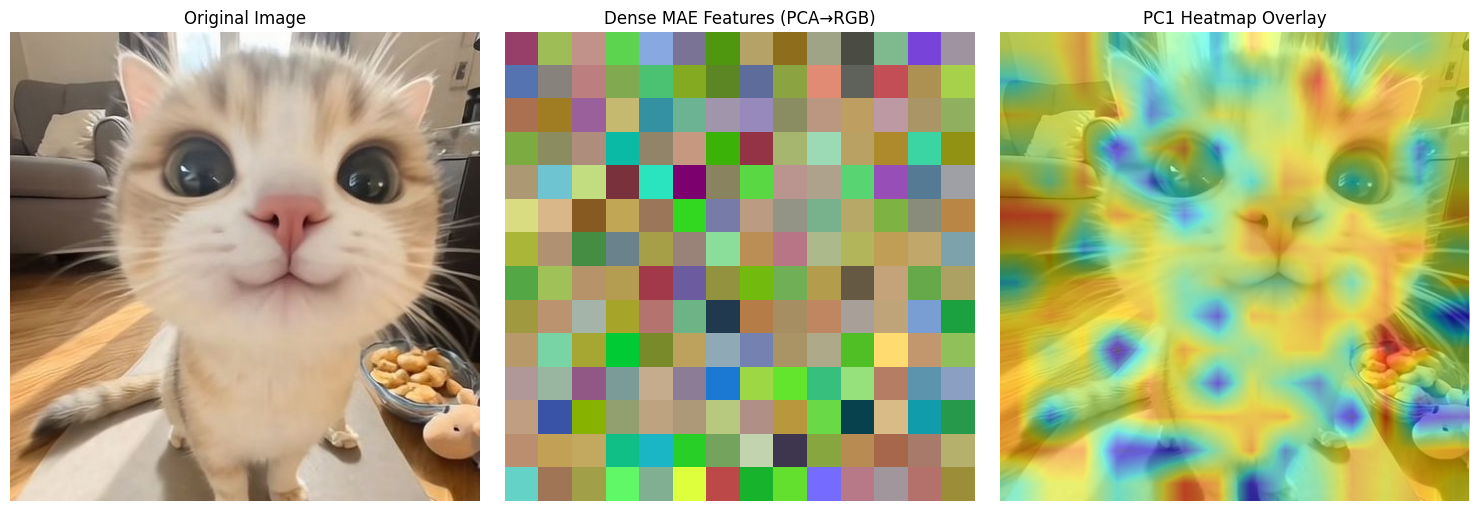

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import ViTMAEModel, AutoImageProcessor
from PIL import Image

# --- 1. Extract dense features with MAE ---
model_name = "facebook/vit-mae-base"  # or vit-mae-large, vit-mae-huge
model = ViTMAEModel.from_pretrained(model_name).eval()
processor = AutoImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

# CRITICAL: MAE defaults to mask_ratio=0.75 — disable it to encode ALL patches
model.config.mask_ratio = 0.0

with torch.no_grad():
    outputs = model(**inputs)

last_hidden = outputs.last_hidden_state   # [B, 1 + N, D]
ids_restore = outputs.ids_restore         # [B, N] — unshuffle indices

# MAE output: [CLS, patch_1, ..., patch_N]  (patches may be in shuffled order)
# No register tokens — standard ViT structure
patch_tokens = last_hidden[:, 1:, :]      # [1, N, D]

# Unshuffle patches back to original spatial order
# ids_restore[i] = original_position_of_shuffled_patch_i
# inv_restore[j] = shuffled_position_of_original_patch_j
N = patch_tokens.shape[1]
inv_restore = torch.argsort(ids_restore[0, :N])
patch_tokens_unshuffled = patch_tokens[0, inv_restore, :]  # [N, D]

# Grid size from config (e.g. 224//16 = 14)
grid_size = model.config.image_size // model.config.patch_size

patch_tokens_np = patch_tokens_unshuffled.numpy()   # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense MAE Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("mae_dense_features.png", dpi=150)
plt.show()